# Vegetation indices and harvest detection

Loads the Sentinel-2 series, computes vegetation indices, detects candidate
harvest dates and plots the time series with the harvests marked.
Figures are saved to `figures/`, tables to `data/processed/`.

In [1]:
# ---- CONFIGURATION (edit here) ----
INDICES_TO_COMPUTE = ["NDVI", "EVI", "NDRE", "NDMI", "NDTI"]
INDICES_TO_PLOT = ["NDVI"]  # 1 or 2 indices
FIELDS_TO_PLOT = [1440, 1460]  # one figure per field
SHOW_HARVESTS = True  # mark candidate harvests with a red asterisk
SAVE_FIGURES = True

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt

from cane_cycle.harvest import detect_harvests
from cane_cycle.io import load_s2_csv
from cane_cycle.plotting import plot_index_timeseries
from cane_cycle.vegetation_indices import add_indices, add_peak_band

# Works whether this runs from the project root or from notebooks/.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = PROJECT_DIR / "data" / "raw" / "fields_example_s2.csv"
INDICES_FILE = PROJECT_DIR / "data" / "processed" / "s2_indices.csv"
HARVEST_FILE = PROJECT_DIR / "data" / "processed" / "harvest_dates.csv"
FIGURES_DIR = PROJECT_DIR / "figures"

In [3]:
df = load_s2_csv(RAW_FILE)
print(f"{len(df)} rows, fields: {sorted(df['field_id'].unique())}")
print(f"from {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
df.head()

1024 rows, fields: [np.int64(1440), np.int64(1460)]
from 2016-03-21 to 2026-09-25


,fonte,date,field_id,granuleID,pixelTotal,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,coverage_pct
0,S2,2016-03-21,1440,L2A_T22K,4599,0.030746,0.033928,0.065326,0.044759,0.094338,0.286814,0.352977,0.342982,0.373373,0.187674,0.095895,100.0
1,S2,2016-04-20,1440,L2A_T22K,4599,0.029278,0.036617,0.072595,0.060994,0.115334,0.291009,0.349394,0.347442,0.378658,0.206581,0.108269,100.0
2,S2,2016-08-08,1440,L2A_T22K,4599,0.050715,0.069155,0.110645,0.153314,0.203109,0.276788,0.308469,0.321489,0.345403,0.339970,0.221604,100.0
3,S2,2016-08-28,1440,L2A_T22K,4599,0.055318,0.073195,0.113827,0.144200,0.188915,0.258332,0.283557,0.293433,0.311559,0.335816,0.231059,100.0
4,S2,2016-09-17,1440,L2A_T22K,4599,0.072596,0.096005,0.140615,0.209306,0.256428,0.293911,0.320923,0.331547,0.364844,0.493490,0.352882,100.0


In [4]:
df = add_indices(df, indices=INDICES_TO_COMPUTE)
df = add_peak_band(df)

INDICES_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(INDICES_FILE, index=False)

df["peak_band"].value_counts()

peak_band
B8A    632
B11    304
B1      58
B8      23
B12      4
B5       1
B2       1
B7       1
Name: count, dtype: int64

In [5]:
harvests = detect_harvests(df)
harvests.to_csv(HARVEST_FILE, index=False)

print(harvests["kind"].value_counts().to_string())
harvests

kind
cane         13
rotation?     6


,field_id,last_green_date,first_dry_date,mid_date,uncertainty_days,green_run_days,kind
0,1440,2016-08-08,2016-08-28,2016-08-18 00:00:00,20,140,rotation?
1,1440,2017-09-12,2017-09-27,2017-09-19 12:00:00,15,180,cane
2,1440,2018-06-19,2018-09-12,2018-07-31 12:00:00,85,105,rotation?
3,1440,2019-04-10,2019-04-15,2019-04-12 12:00:00,5,15,rotation?
4,1440,2020-05-09,2020-05-19,2020-05-14 00:00:00,10,210,cane
5,1440,2021-08-22,2021-09-01,2021-08-27 00:00:00,10,235,cane
6,1440,2022-09-11,2022-10-01,2022-09-21 00:00:00,20,265,cane
7,1440,2023-08-22,2023-09-01,2023-08-27 00:00:00,10,300,cane
8,1440,2024-04-03,2024-04-08,2024-04-05 12:00:00,5,40,rotation?
9,1440,2025-06-12,2025-06-17,2025-06-14 12:00:00,5,210,cane


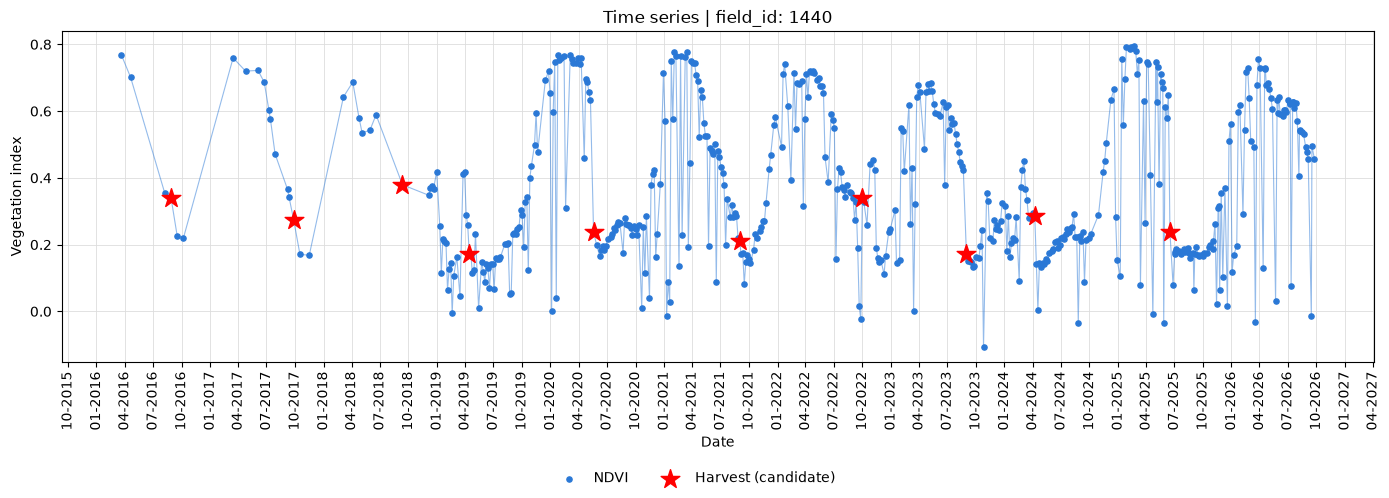

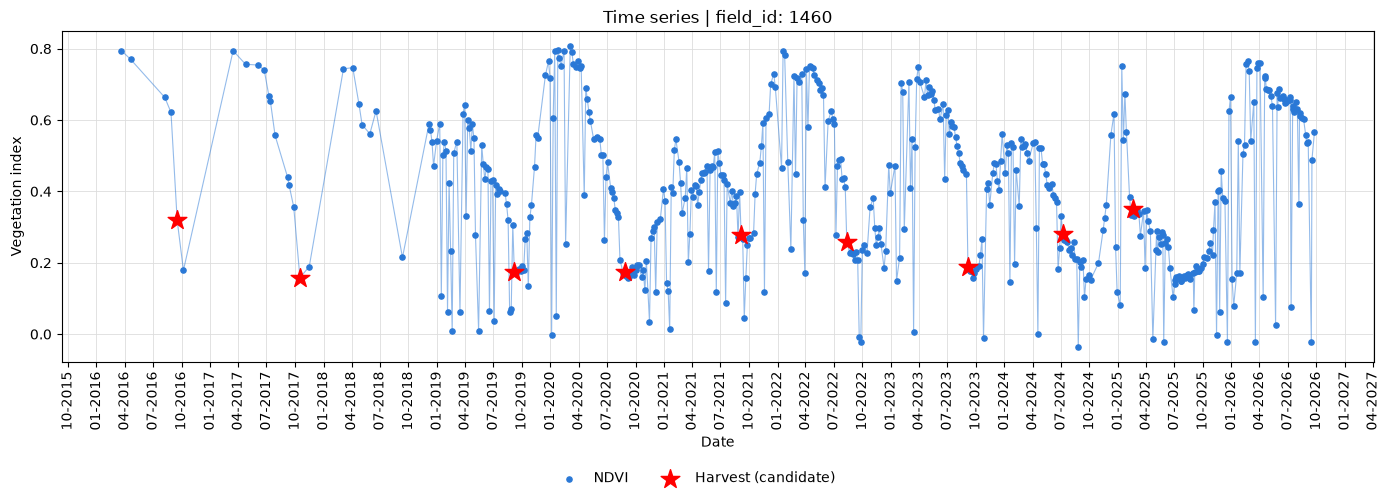

In [6]:
for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        file_name = f"timeseries_{field_id}_{'_'.join(INDICES_TO_PLOT)}.png"
        save_path = FIGURES_DIR / file_name
    plot_index_timeseries(
        df,
        INDICES_TO_PLOT,
        field_id,
        harvests=harvests if SHOW_HARVESTS else None,
        save_path=save_path,
    )
    plt.show()